<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/11_Music_Genre_Classification_using_LSTM_%5BDataset_GTZAN_Music_Genre_Dataset_%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub librosa
import kagglehub
path = kagglehub.dataset_download('andradaolteanu/gtzan-dataset-music-genre-classification')
print(path)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
/kaggle/input/gtzan-dataset-music-genre-classification


In [ ]:
import os, glob, numpy as np, matplotlib.pyplot as plt, librosa
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# 1. locate the audio folder  (Data/genres_original/<genre>/<genre>.000xx.wav)
audio_root = None
for r, d, f in os.walk(path):
    if os.path.basename(r) == 'genres_original':
        audio_root = r; break
genres = sorted(os.listdir(audio_root))
print(genres)

SR, SEG_SEC, N_MFCC, HOP = 22050, 3, 20, 1024
FILES_PER_GENRE = 100          # use 30 for a quick test run

files, labels = [], []
for gi, g in enumerate(genres):
    fl = sorted(glob.glob(f'{audio_root}/{g}/*.wav'))[:FILES_PER_GENRE]
    files += fl; labels += [gi] * len(fl)

# 2. split by SONG (so pieces of the same song never appear in both train and test)
f_tr, f_te, l_tr, l_te = train_test_split(files, labels, test_size=0.2, stratify=labels, random_state=42)
print("train songs:", len(f_tr), " test songs:", len(f_te))

['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
train songs: 800  test songs: 200


In [ ]:
# 3. Feature extraction: each song -> ten 3-second pieces -> MFCC matrix (65 time steps x 20 coefficients)
def extract(file_list, label_list):
    X, y = [], []
    n = SR * SEG_SEC
    for f, l in zip(file_list, label_list):
        try:
            sig, _ = librosa.load(f, sr=SR, duration=30)
        except Exception as e:                       # GTZAN has one corrupted file (jazz.00054)
            print("skipped:", os.path.basename(f)); continue
        for s in range(len(sig) // n):
            seg = sig[s * n:(s + 1) * n]
            mfcc = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC, hop_length=HOP).T     # (time, n_mfcc)
            X.append(mfcc); y.append(l)
    return np.array(X), np.array(y)

X_tr, y_tr = extract(f_tr, l_tr)
X_te, y_te = extract(f_te, l_te)
print("X_train:", X_tr.shape, " X_test:", X_te.shape)

# 4. normalise using training statistics
mu, sd = X_tr.mean(axis=(0, 1)), X_tr.std(axis=(0, 1)) + 1e-8
X_tr, X_te = (X_tr - mu) / sd, (X_te - mu) / sd

/tmp/ipykernel_12441/809525790.py:7: UserWarning: PySoundFile failed. Trying audioread instead.
  sig, _ = librosa.load(f, sr=SR, duration=30)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


skipped: jazz.00054.wav
X_train: (7981, 65, 20)  X_test: (2000, 65, 20)


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 5. LSTM model
model = keras.Sequential([
    layers.Input(shape=X_tr.shape[1:]),                       # (65 time steps, 20 MFCCs)
    layers.LSTM(128, return_sequences=True),
    layers.Dropout(0.3),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(genres), activation='softmax')
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

early = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True)
history = model.fit(X_tr, y_tr, validation_split=0.1, epochs=40, batch_size=64, callbacks=[early])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 65, 128)        │        76,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 65, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,506 (509.79 KB)

 Trainable params: 130,506 (509.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 26s 196ms/step - accuracy: 0.4077 - loss: 1.6796 - val_accuracy: 0.5106 - val_loss: 1.4271
Epoch 2/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 41s 201ms/step - accuracy: 0.5728 - loss: 1.2466 - val_accuracy: 0.5970 - val_loss: 1.2928
Epoch 3/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 188ms/step - accuracy: 0.6423 - loss: 1.0655 - val_accuracy: 0.6258 - val_loss: 1.2576
Epoch 4/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 23s 207ms/step - accuracy: 0.6708 - loss: 0.9810 - val_accuracy: 0.5544 - val_loss: 1.3743
Epoch 5/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 41s 204ms/step - accuracy: 0.7125 - loss: 0.8669 - val_accuracy: 0.5995 - val_loss: 1.3839
Epoch 6/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 23s 204ms/step - accuracy: 0.7374 - loss: 0.7906 - val_accuracy: 0.6008 - val_loss: 1.3332
Epoch 7/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 22s 191ms/step - accuracy: 0.7555 - loss: 0.7306 - val_accuracy: 0.6270 - val_loss: 1.3603
Epoch 8/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 23s 202ms/step - accuracy: 0.7762 - loss: 0

Test accuracy (3-second pieces): 62.95%
              precision    recall  f1-score   support

       blues       0.70      0.67      0.68       200
   classical       0.82      0.92      0.87       200
     country       0.61      0.57      0.59       200
       disco       0.40      0.34      0.37       200
      hiphop       0.54      0.62      0.58       200
        jazz       0.71      0.80      0.75       200
       metal       0.79      0.67      0.73       200
         pop       0.62      0.76      0.68       200
      reggae       0.57      0.56      0.57       200
        rock       0.49      0.38      0.43       200

    accuracy                           0.63      2000
   macro avg       0.62      0.63      0.62      2000
weighted avg       0.62      0.63      0.62      2000



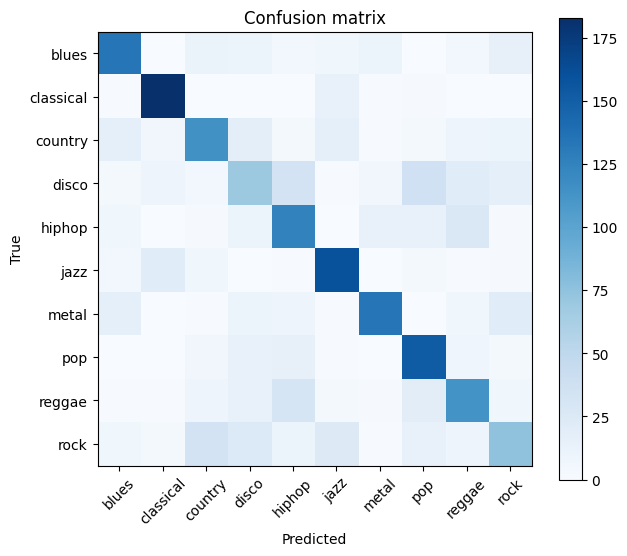

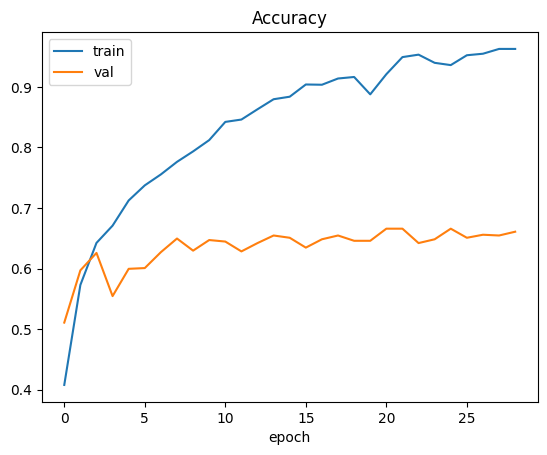

Song: classical.00071.wav | Predicted: classical | True: classical


In [ ]:
# 6. Evaluate on unseen songs
loss, acc = model.evaluate(X_te, y_te, verbose=0)
print(f"Test accuracy (3-second pieces): {acc*100:.2f}%")

y_pred = np.argmax(model.predict(X_te, verbose=0), axis=1)
print(classification_report(y_te, y_pred, target_names=genres))

cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(10), genres, rotation=45); plt.yticks(range(10), genres)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix'); plt.show()

plt.plot(history.history['accuracy'], label='train'); plt.plot(history.history['val_accuracy'], label='val')
plt.legend(); plt.title('Accuracy'); plt.xlabel('epoch'); plt.show()

# predict genre of one test song = majority vote over its 3-second pieces
i = 0
song = f_te[i]
sig, _ = librosa.load(song, sr=SR, duration=30)
n = SR * SEG_SEC
pieces = np.array([librosa.feature.mfcc(y=sig[s*n:(s+1)*n], sr=SR, n_mfcc=N_MFCC, hop_length=HOP).T for s in range(len(sig)//n)])
votes = np.argmax(model.predict((pieces - mu) / sd, verbose=0), axis=1)
print("Song:", os.path.basename(song), "| Predicted:", genres[np.bincount(votes).argmax()], "| True:", genres[l_te[i]])

In [ ]:
1. What is the problem?

It is exactly Problem 10: take a music clip and say which of the 10 genres it belongs to. The only difference is the model. We replace the SimpleRNN layers with LSTM layers to get better accuracy.

2. The dataset and the data pipeline (same as Problem 10)

Nothing changes here:

GTZAN: 1,000 songs (10 genres × 100), 30 seconds each.
Split the songs 80/20 first, to avoid data leakage.
Cut each song into ten 3-second pieces.
Extract MFCC features: 20 numbers per frame, which gives a 65 × 20 sequence for each piece.
Normalise using the training mean and standard deviation.
3. What is the solution?

The LSTM is what you learned in Problem 4. A quick revision for this problem:

Part	Meaning in simple words
Cell state	Long-term memory, like a notebook running through the whole clip
Forget gate	Decides what to erase
Input gate	Decides what new information to write
Output gate	Decides what to pass on as output

Why LSTM suits music better than a SimpleRNN: a genre shows up in patterns like rhythm, instrument texture and repeated beats, spread across many frames. A SimpleRNN forgets the early frames (vanishing gradient). The LSTM's cell state carries information across all 65 frames, so it can use patterns that appear early in the clip.

############code##############
Everything is the same as Program 10, except the two layers:

python
model = keras.Sequential([
    layers.Input(shape=X_tr.shape[1:]),                  # (65, 20)
    layers.LSTM(128, return_sequences=True),             # <-- was SimpleRNN
    layers.Dropout(0.3),
    layers.LSTM(64),                                     # <-- was SimpleRNN
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(genres), activation='softmax')
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
early = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True)
history = model.fit(X_tr, y_tr, validation_split=0.1, epochs=40, batch_size=64, callbacks=[early])
return_sequences=True on the first LSTM gives the full sequence to the second.
EarlyStopping, evaluation, the classification report, the confusion matrix and the majority-vote song prediction work just like Program 10.

Time-saving tip for the exam: the slow step is feature extraction (loading 1,000 songs and computing MFCCs), not training. If you already ran Program 10 in the same session, the arrays X_tr, X_te, y_tr, y_te already exist. Then you only need to run the model, training and evaluation cells. In a fresh session you must run all the cells from the top. Don't change anything in the pipeline.

5. The output you will see
The genre list, and train songs: 800 test songs: 200.
X_train: (~8000, 65, 20), as in Program 10.
The model summary with LSTM layers of 76,288 and 49,408 parameters.
The training log. The LSTM trains faster per epoch on a GPU (it has a fast GPU kernel), and the accuracy should climb higher than the RNN did.
Test accuracy of roughly 60–75%. I haven't run it on the real dataset, so go by your own number. A few percent above your RNN's ~55% is the expected result.
The classification report and the confusion matrix. Classical, jazz and metal score best, and rock, country and blues are the hardest.
The last line: a song name with the predicted and true genre (by majority vote over its ten pieces).
6. RNN vs LSTM on the same data (the most likely viva question)
	Program 10: SimpleRNN	Program 11: LSTM
Memory	Short-term only	Long-term (cell state) plus short-term
Gates	None	Forget, input, output
Vanishing gradient	Suffers	Largely solved
Parameters (128 + 64 units)	19,072 + 12,352	76,288 + 49,408
Typical accuracy	About 50–60%	About 60–75%

"On the same MFCC features, the LSTM beats the RNN because its gates and cell state keep long-term information, which avoids the vanishing gradient problem."

If your LSTM score is only a few percent better, that is fine. Say: "The LSTM improves on the RNN, and the limit here is the short 3-second clips and the small dataset."

###########BLOCK#####################
          START
            |
            v
       Load GTZAN Dataset
            |
            v
        Load Audio Files
             (.wav)
            |
            v
        Split Songs
        Train / Test
            |
            v
       Audio Preprocessing
        (22050 Hz)
            |
            v
       Divide into 3-sec
          Segments
            |
            v
       Extract MFCC Features
         (20 Coefficients)
            |
            v
        Normalize Features
            |
            v
         Build LSTM Model
            |
            v
          LSTM (128)
       Return Sequences
            |
            v
           Dropout
            |
            v
          LSTM (64)
            |
            v
           Dropout
            |
            v
        Dense + Softmax
            |
            v
         Train Model
            |
            v
        Evaluate Model
            |
            v
       Predict Music Genre
            |
            v
           STOP
##################QUE##########
Why is the LSTM better than the RNN for music? The gates and the cell state keep long-term information and avoid vanishing gradients, so patterns spread across many frames are learned.
Explain the gates of an LSTM. The forget gate erases old information, the input gate adds new information, and the output gate decides what is passed on as the hidden state.
What is the input shape? (batch, 65 time steps, 20 MFCC features).
Why 4 × ... parameters? There are four weight sets: forget gate, input gate, candidate and output gate.
What is MFCC and why use it? A compact representation of the sound's spectral shape on the mel scale. It reduces 66,150 raw audio numbers per 3 seconds to 65 × 20.
How is a whole song's genre predicted? Predict every 3-second piece and take the majority vote.
How can you reduce overfitting? Dropout, EarlyStopping, data augmentation (adding noise, pitch shifting, time stretching), a smaller model, or more data.
Why do you need a classification report and a confusion matrix? Accuracy alone hides which genres get confused. The report gives precision, recall and F1 per genre.
What are the alternatives? GRU (fewer gates, faster), Bi-LSTM (reads the sequence forward and backward), or a CNN on spectrogram images.
Which loss and last layer? Softmax with sparse categorical cross-entropy for 10 mutually exclusive classes.